# Causal S-Learner & Counterfactual Treatment Standardization

### Biostatistical Problem Solved:
In observational cancer data, observed survival ($Y$) is **already contaminated by variations in treatment received** (e.g. patients who received 60 Gy lived longer partly due to treatment, while patients who received 20 Gy had truncated survival). Without adjustment, a baseline model is forced to explain treatment differences using imaging features.

### The Causal S-Learner (G-Computation) Solution:
1. **During Training (Conditioning on Treatment)**:
   We include radiobiological treatment parameters ($BED_{10}$, dose, fractions) alongside baseline features (Age, WHO status, Tumor Volume, $t_0$ Radiomics). Because dose is explicitly controlled in the regression, the baseline biological coefficients are **statistically adjusted for treatment**.
2. **At Inference (Counterfactual Standardization)**:
   We evaluate two distinct prediction modes on the holdout test cohort:
   - **Mode A (Observed Survival $\hat{Y}_{\text{obs}}$)**: Evaluates actual observed treatment doses to benchmark against real test weeks.
   - **Mode B (Standardized Survival $\hat{Y}_{60\text{Gy}}$)**: Fixes treatment to the standard Stupp protocol (60 Gy / 30 fx, $BED_{10} = 72$ Gy) for **all** patients, revealing each patient's intrinsic biological prognosis under uniform standard-of-care.
   - **Mode C (Treatment Effect $\Delta$)**: Estimates the survival gain/deficit ($ITE = \hat{Y}_{60\text{Gy}} - \hat{Y}_{\text{obs}}$) attributable to treatment disparities.

## 1. Environment & Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import RidgeCV, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
print("Libraries successfully imported.")

Libraries successfully imported.


## 2. Load Datasets

In [2]:
clinical = pd.read_csv("data/CFB-GBM_clinical_data_v03_20260619.tsv", sep="\t")
treatment = pd.read_csv("data/CFB-GBM_treatment_data_v02_20260129.tsv", sep="\t")
rano = pd.read_csv("data/CFB-GBM_rano_criteria_v04_20260909.tsv", sep="\t")
features = pd.read_csv("data/CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv", sep="\t")

print(f"Loaded Clinical:  {clinical.shape}")
print(f"Loaded Treatment: {treatment.shape}")
print(f"Loaded RANO:      {rano.shape}")
print(f"Loaded Radiomics: {features.shape}")

Loaded Clinical:  (264, 8)
Loaded Treatment: (264, 4)
Loaded RANO:      (165, 10)
Loaded Radiomics: (2424, 150)


## 3. Feature Extraction & Radiobiological Harmonization

In [3]:
target_col = clinical.columns[1]  # "survival (weeks)"
id_col = "id_patient"
print(f"Target column: '{target_col}'")

# 1. Clinical Base Table
df_base = clinical.copy()

# 2. Treatment Radiobiological Parameterization
t_df = treatment.copy()
dose_col = "dose (Gy)"
frac_col = "fractions_number"
delay_col = "delay_t0_to_radiotherapy (weeks)"

t_df["treatment_recorded"] = t_df[dose_col].notna().astype(int)
t_df[dose_col] = pd.to_numeric(t_df[dose_col], errors="coerce")
t_df[frac_col] = pd.to_numeric(t_df[frac_col], errors="coerce")
t_df[delay_col] = pd.to_numeric(t_df[delay_col], errors="coerce")

# Calculate radiobiology metrics where recorded
has_dose = (t_df[dose_col] > 0) & (t_df[frac_col] > 0)
t_df["treatment_dose_per_fraction"] = np.where(has_dose, t_df[dose_col] / t_df[frac_col], np.nan)

alpha_beta = 10.0
dpf = t_df["treatment_dose_per_fraction"]
t_df["treatment_bed10"] = np.where(has_dose, t_df[dose_col] * (1.0 + (dpf / alpha_beta)), np.nan)

# Regimen Indicators
t_df["treatment_is_standard_60gy"] = np.where(t_df[dose_col].isna(), np.nan, (t_df[dose_col] >= 54.0).astype(float))
t_df["treatment_is_hypofractionated"] = np.where(t_df[dose_col].isna(), np.nan, ((t_df[dose_col] >= 34.0) & (t_df[dose_col] < 54.0)).astype(float))

df_base = df_base.merge(t_df, on=id_col, how="left")

# 3. Baseline Tumor Volume (RANO t0 only)
rano_base_cols = [c for c in ["id_patient", "size_t0 (cm3)"] if c in rano.columns]
if len(rano_base_cols) > 1:
    rano_sub = rano[rano_base_cols].drop_duplicates(subset=[id_col])
    df_base = df_base.merge(rano_sub, on=id_col, how="left")

clinical_treatment_cols = [
    c for c in df_base.columns if c not in [id_col, target_col]
]

# 4. PyRadiomics Baseline (t0, primary sequences T1gd & FLAIR)
feat_df = features.copy()
if "Patient" in feat_df.columns:
    feat_df = feat_df.rename(columns={"Patient": id_col})
if "Temporality" in feat_df.columns:
    feat_df = feat_df[feat_df["Temporality"] == "t0"]
if "Sequence" in feat_df.columns:
    feat_df = feat_df[feat_df["Sequence"].isin(["t1gd", "flair"])]

rad_cols = [c for c in feat_df.columns if c.startswith("original_")]
if rad_cols and "Sequence" in feat_df.columns:
    feat_df[rad_cols] = feat_df[rad_cols].apply(pd.to_numeric, errors="coerce")
    rad_pivot = feat_df.pivot_table(
        index=id_col,
        columns="Sequence",
        values=rad_cols,
        aggfunc="mean"
    )
    rad_pivot.columns = [f"rad_{seq}_{col}" for col, seq in rad_pivot.columns]
    rad_pivot = rad_pivot.reset_index()
    df_master = df_base.merge(rad_pivot, on=id_col, how="left")
else:
    df_master = df_base.copy()

# Filter valid target
valid_mask = df_master[target_col].notna() & (pd.to_numeric(df_master[target_col], errors="coerce") > 0)
clean_df = df_master[valid_mask].copy()

radiomics_cols = [c for c in clean_df.columns if c.startswith("rad_")]
print(f"Harmonized cohort: {len(clean_df)} patients.")
print(f"Stage 1 Clinical/Treatment features: {len(clinical_treatment_cols)}, Stage 2 Radiomics pool: {len(radiomics_cols)}")

Target column: 'survival (weeks)'
Harmonized cohort: 264 patients.
Stage 1 Clinical/Treatment features: 15, Stage 2 Radiomics pool: 214


## 4. Partition and Save Holdout Test Set

In [4]:
TEST_RATIO = 0.15
RANDOM_SEED = 42

train_df, test_df = train_test_split(
    clean_df, test_size=TEST_RATIO, random_state=RANDOM_SEED
)

test_file_path = "test_dataset_causal_holdout.csv"
test_df.to_csv(test_file_path, index=False)
print(f"Causal holdout test set ({len(test_df)} patients) saved to '{test_file_path}'")
print(f"Training partition: {len(train_df)} patients.")

y_train_raw = pd.to_numeric(train_df[target_col], errors="coerce")
y_train_log = np.log1p(y_train_raw)

X_train_clin = train_df[clinical_treatment_cols].copy()
X_train_rad = train_df[radiomics_cols].copy()

Causal holdout test set (40 patients) saved to 'test_dataset_causal_holdout.csv'
Training partition: 224 patients.


## 5. Stage 1: Fit Clinical + Treatment Control Core

By including radiotherapy dose and $BED_{10}$ alongside baseline clinical variables, Stage 1 estimates the effect of patient biology **while controlling for treatment**.

In [5]:
cat_clin_cols = X_train_clin.select_dtypes(include=["object", "category"]).columns.tolist()
num_clin_cols = X_train_clin.select_dtypes(include=["number"]).columns.tolist()

clin_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_clin_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), cat_clin_cols)
    ]
)

stage1_pipeline = Pipeline([
    ("prep", clin_preprocessor),
    ("ridge", RidgeCV(alphas=[0.01, 0.1, 0.5, 1.0, 3.0, 10.0]))
])

stage1_pipeline.fit(X_train_clin, y_train_log)
y_train_clin_pred_log = stage1_pipeline.predict(X_train_clin)

# Duan's Smearing Factor
e_stage1 = y_train_log - y_train_clin_pred_log
smearing_stage1 = np.mean(np.exp(e_stage1))

y_train_clin_pred_weeks = np.maximum(0.0, smearing_stage1 * np.exp(y_train_clin_pred_log) - 1.0)
residuals_train = y_train_log - y_train_clin_pred_log

print(f"Stage 1 Ridge optimal alpha: {stage1_pipeline.named_steps['ridge'].alpha_:.4f}")
print(f"Stage 1 Train R² (log-space): {r2_score(y_train_log, y_train_clin_pred_log):.4f}")
print(f"Stage 1 Duan Smearing Factor: {smearing_stage1:.4f}")

Stage 1 Ridge optimal alpha: 10.0000
Stage 1 Train R² (log-space): 0.2178
Stage 1 Duan Smearing Factor: 1.3030


## 6. Stage 2: Fit Radiomics Residual Model

Because Stage 1 controlled for treatment, the residual variance represents unexplained biological variation **free from treatment confounding**.

In [6]:
k_screen = min(15, X_train_rad.shape[1])

rad_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_regression, k=k_screen))
])

cv_folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

stage2_pipeline = Pipeline([
    ("prep", rad_preprocessor),
    ("elastic_net", ElasticNetCV(
        l1_ratio=[0.05, 0.2, 0.5, 0.8],
        alphas=np.logspace(-4, -0.5, 50),
        cv=cv_folds,
        max_iter=10000,
        random_state=RANDOM_SEED
    ))
])

stage2_pipeline.fit(X_train_rad, residuals_train)

# Combined training predictions & Combined Smearing Factor
y_train_rad_res_pred = stage2_pipeline.predict(X_train_rad)
y_train_combined_log = y_train_clin_pred_log + y_train_rad_res_pred
e_combined = y_train_log - y_train_combined_log
smearing_combined = np.mean(np.exp(e_combined))

n_nonzero_rad = (stage2_pipeline.named_steps["elastic_net"].coef_ != 0).sum()
print(f"Stage 2 ElasticNet optimal alpha: {stage2_pipeline.named_steps['elastic_net'].alpha_:.5f}")
print(f"Active non-zero radiomic biomarkers: {n_nonzero_rad} of {k_screen}")
print(f"Combined Two-Stage Smearing Factor: {smearing_combined:.4f}")

Stage 2 ElasticNet optimal alpha: 0.07197
Active non-zero radiomic biomarkers: 6 of 15
Combined Two-Stage Smearing Factor: 1.2671


## 7. Inference & Counterfactual Treatment Standardization

We reload the holdout test set (`test_dataset_causal_holdout.csv`) and evaluate:
1. **Observed Treatment Predictions ($\hat{Y}_{\text{obs}}$)**: Evaluates actual patient-specific treatments against observed survival.
2. **Standardized Counterfactual Predictions ($\hat{Y}_{60\text{Gy}}$)**: Clones the test cohort and fixes treatment for **all** patients to standard-of-care Stupp protocol (60 Gy / 30 fx, $BED_{10} = 72.0$).
3. **Individual Treatment Effect ($\text{ITE} = \hat{Y}_{60\text{Gy}} - \hat{Y}_{\text{obs}}$)**: Quantifies the estimated survival gain if sub-standardly treated patients had received full 60 Gy.

Loaded causal holdout test cohort: 40 patients.

--- Verification of Causal Standardization & Spread ---


,Actual Test Survival,Observed Pred (Actual Dose),Standardized Pred (Uniform 60 Gy),Counterfactual Gain (ITE Weeks)
count,40.0,40.0,40.0,40.0
mean,66.9,63.6,72.7,9.1
std,45.5,30.0,25.8,11.1
min,7.0,15.6,29.3,0.0
25%,39.0,45.5,55.6,0.0
50%,55.5,56.9,65.9,0.0
75%,83.2,75.8,83.4,17.5
max,228.0,144.5,144.5,34.4



Observed Benchmark on Independent Holdout Test Set:


,Observed Multi-Modal Model
R² Score,-0.111
RMSE (weeks),47.306
MAE (weeks),35.810
Spearman Rank Correlation (ρ),0.086


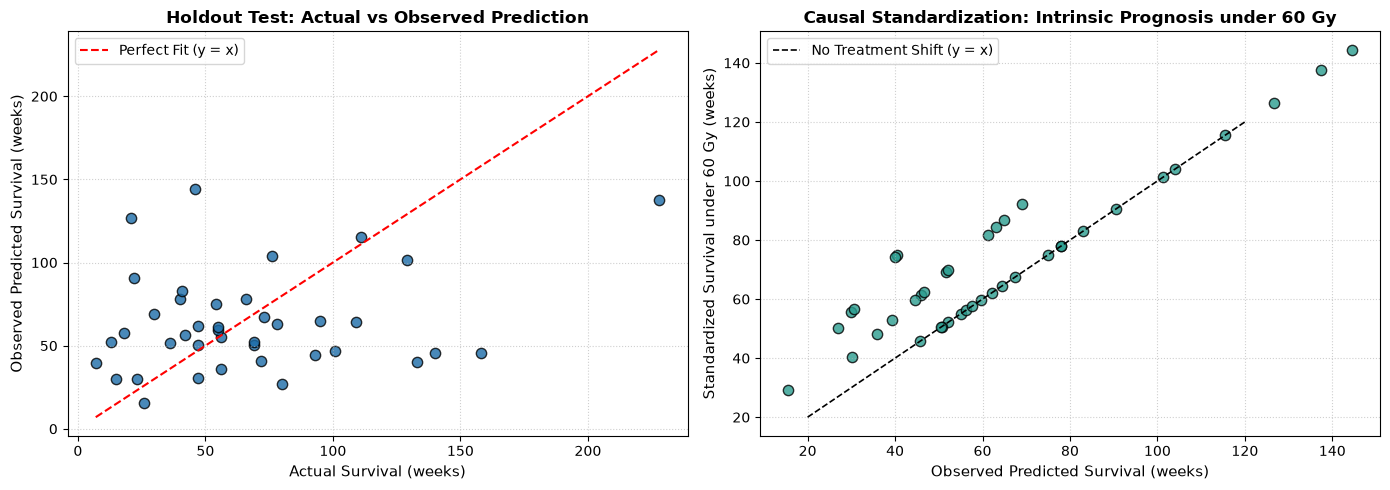

In [9]:
saved_test_df = pd.read_csv("test_dataset_causal_holdout.csv")
print(f"Loaded causal holdout test cohort: {len(saved_test_df)} patients.")

y_test_raw = pd.to_numeric(saved_test_df[target_col], errors="coerce")
X_test_clin_obs = saved_test_df[clinical_treatment_cols].copy()
X_test_rad = saved_test_df[radiomics_cols].copy()

# --- 1. Mode A: Observed Predictions (Actual Treatment) ---
y_test_clin_obs_log = stage1_pipeline.predict(X_test_clin_obs)
y_test_rad_res_log = stage2_pipeline.predict(X_test_rad)
y_test_obs_log = y_test_clin_obs_log + y_test_rad_res_log
y_test_obs_pred = np.maximum(0.0, smearing_combined * np.exp(y_test_obs_log) - 1.0)

# --- 2. Mode B: Standardized Counterfactual (Fix ALL patients to 60 Gy / 30 fx) ---
X_test_clin_standard = X_test_clin_obs.copy()
X_test_clin_standard["dose (Gy)"] = 60.0
X_test_clin_standard["fractions_number"] = 30.0
X_test_clin_standard["treatment_dose_per_fraction"] = 2.0
X_test_clin_standard["treatment_bed10"] = 60.0 * (1.0 + 2.0 / 10.0)  # 72.0 Gy
X_test_clin_standard["treatment_is_standard_60gy"] = 1.0
X_test_clin_standard["treatment_is_hypofractionated"] = 0.0
X_test_clin_standard["treatment_recorded"] = 1.0

y_test_clin_std_log = stage1_pipeline.predict(X_test_clin_standard)
y_test_std_log = y_test_clin_std_log + y_test_rad_res_log
y_test_std_pred = np.maximum(0.0, smearing_combined * np.exp(y_test_std_log) - 1.0)

# --- 3. Mode C: Individual Treatment Effect (ITE Gain) ---
treatment_effect_gain = y_test_std_pred - y_test_obs_pred

# Summary Comparison
eval_summary = pd.DataFrame({
    "Actual Test Survival": y_test_raw.describe(),
    "Observed Pred (Actual Dose)": pd.Series(y_test_obs_pred).describe(),
    "Standardized Pred (Uniform 60 Gy)": pd.Series(y_test_std_pred).describe(),
    "Counterfactual Gain (ITE Weeks)": pd.Series(treatment_effect_gain).describe()
})
print("\n--- Verification of Causal Standardization & Spread ---")
display(eval_summary.round(1))

# Benchmark Metrics for Observed Prediction
def calc_metrics(y_true, y_pred):
    return [
        r2_score(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        mean_absolute_error(y_true, y_pred),
        spearmanr(y_true, y_pred)[0]
    ]

obs_metrics = pd.DataFrame({
    "Observed Multi-Modal Model": calc_metrics(y_test_raw, y_test_obs_pred)
}, index=["R² Score", "RMSE (weeks)", "MAE (weeks)", "Spearman Rank Correlation (ρ)"])

print("\nObserved Benchmark on Independent Holdout Test Set:")
display(obs_metrics.round(3))

# Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Observed Actual vs Predicted
axes[0].scatter(y_test_raw, y_test_obs_pred, color="#1b6ca8", edgecolors="k", s=55, alpha=0.8)
lims = [min(y_test_raw.min(), y_test_obs_pred.min()), max(y_test_raw.max(), y_test_obs_pred.max())]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Perfect Fit (y = x)")
axes[0].set_xlabel("Actual Survival (weeks)", fontsize=11)
axes[0].set_ylabel("Observed Predicted Survival (weeks)", fontsize=11)
axes[0].set_title("Holdout Test: Actual vs Observed Prediction", fontsize=12, fontweight="bold")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Counterfactual Shift (Observed vs Standardized 60 Gy)
axes[1].scatter(y_test_obs_pred, y_test_std_pred, color="#2a9d8f", edgecolors="k", s=55, alpha=0.8)
axes[1].plot([20, 120], [20, 120], "k--", lw=1.2, label="No Treatment Shift (y = x)")
axes[1].set_xlabel("Observed Predicted Survival (weeks)", fontsize=11)
axes[1].set_ylabel("Standardized Survival under 60 Gy (weeks)", fontsize=11)
axes[1].set_title("Causal Standardization: Intrinsic Prognosis under 60 Gy", fontsize=12, fontweight="bold")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 8. Selected Biological Radiomic Biomarkers (Treatment-Adjusted)

Selected Non-zero Biomarkers: 6 out of 15 screened.


,Feature,Residual_Coefficient,Abs_Coefficient
10,rad_flair_original_glszm_SmallAreaEmphasis,0.0976,0.0976
9,rad_flair_original_glszm_SizeZoneNonUniformity...,0.0741,0.0741
2,rad_t1gd_original_gldm_DependenceNonUniformity,-0.0445,0.0445
5,rad_flair_original_glrlm_RunLengthNonUniformity,-0.0316,0.0316
8,rad_t1gd_original_glszm_GrayLevelNonUniformity,-0.0101,0.0101
6,rad_t1gd_original_glrlm_RunLengthNonUniformity,-0.0050,0.0050


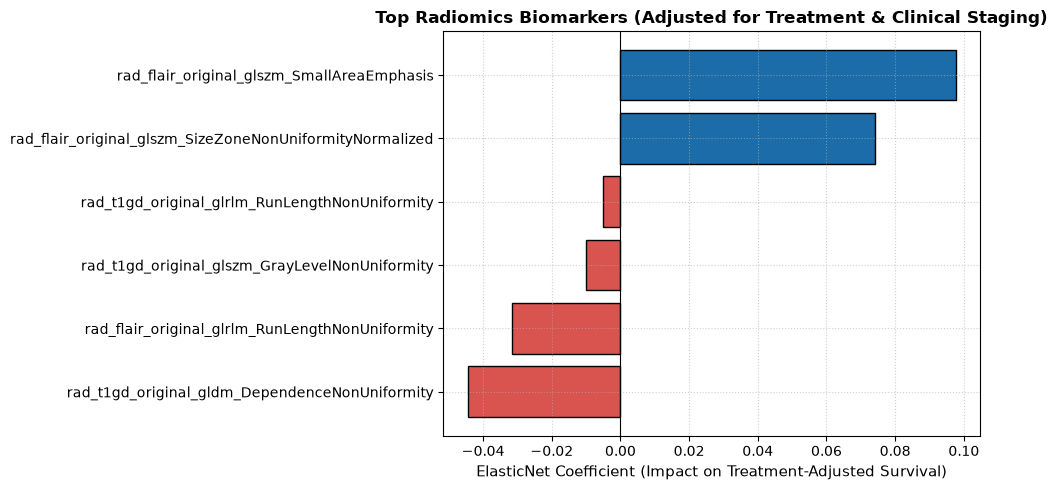

In [8]:
selector = stage2_pipeline.named_steps["prep"].named_steps["selector"]
support = selector.get_support()
selected_rad_names = np.array(radiomics_cols)[support]
en_coefs = stage2_pipeline.named_steps["elastic_net"].coef_

rad_coef_df = pd.DataFrame({
    "Feature": selected_rad_names,
    "Residual_Coefficient": en_coefs,
    "Abs_Coefficient": np.abs(en_coefs)
}).sort_values("Abs_Coefficient", ascending=False)

non_zero_rad = rad_coef_df[rad_coef_df["Residual_Coefficient"] != 0].copy()
print(f"Selected Non-zero Biomarkers: {len(non_zero_rad)} out of {len(selected_rad_names)} screened.")
display(non_zero_rad.round(4))

if not non_zero_rad.empty:
    plot_df = non_zero_rad.head(10).sort_values("Residual_Coefficient", ascending=True)
    colors = ["#1b6ca8" if c > 0 else "#d9534f" for c in plot_df["Residual_Coefficient"]]
    plt.figure(figsize=(10, 5))
    plt.barh(plot_df["Feature"], plot_df["Residual_Coefficient"], color=colors, edgecolor="black")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.title("Top Radiomics Biomarkers (Adjusted for Treatment & Clinical Staging)", fontsize=12, fontweight="bold")
    plt.xlabel("ElasticNet Coefficient (Impact on Treatment-Adjusted Survival)", fontsize=11)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()